# Forecasting Next-Week Volatility of S&P 500 Stocks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/qqgjyx/AC-209A_VolForecast/blob/main/ms3.ipynb)

**Milestone 3: exploratory data analysis, baseline models and the modeling pipeline.**

Canvas project group 38: Ashley Lee, Juntang Wang, Shuo Yang, Simon Manivong, Terry Su.
TF mentor: Daniel More Torres. Project 12 on the approved projects list.

**Contents**

0. [Setup](#Setup)
1. [Project question](#1.-Project-question)
2. [Exploratory data analysis](#2.-Exploratory-data-analysis) (2a-2l), with factor research beyond the course in 2g-2k
3. [Baseline models](#3.-Baseline-models)
4. [Results on the validation years](#4.-Results-on-the-validation-years) (4a-4i)
5. [The modeling pipeline](#5.-The-modeling-pipeline)
6. [Guard and exported numbers](#Guard-and-exported-numbers)

Milestone 2 (`ms2.ipynb`) got, cleaned and joined the data into the stock-week table this notebook
starts from. The code lives in `src/volforecast/`; this notebook calls it and shows the results.
**The test years 2019-2026 stay sealed**: right after loading, every test target is blanked and
every price after the last validation week is dropped, so only the size of the test split appears
(2a) and no model is fit or scored on it. A row belongs to the test years when its target week
does: the last Friday of 2018 forecasts the first week of 2019, so validation stops a week early.
EDA uses the training years 2005-2015, and every model is scored on the validation years 2016-2018.

## Setup

**This notebook runs on its own.** On a first run the next cell downloads the team bucket (Google
Drive, private to the team and the TF): every cache Milestone 2 filled, and the `volforecast`
package, which it installs when missing. No repository, keys or accounts are needed. A full run
takes about ten minutes on a laptop; the genetic-programming search in 2k and the ridge and lasso
grid in 4b take most of it. To fetch from the sources instead, see the Setup section of `ms2.ipynb`.

In [1]:
import os
import sys
from contextlib import suppress
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if not IN_COLAB:  # reload src/ edits; Colab's IPython autoreload imports `imp`, gone since 3.12
    %load_ext autoreload
    %autoreload 2
with suppress(ImportError):  # a fresh Colab has neither python-dotenv's .env nor the package
    from dotenv import load_dotenv

    load_dotenv(Path(".env"))  # API keys or BUCKET_ID="", if a .env exists

BUCKET_ID = os.environ.get("BUCKET_ID", "1dgnWrDZqHPoRjPwwVk9vpvgDBp5r_tC9")  # Google Drive file id
if BUCKET_ID and not Path("data/prices").exists():  # once: unpacks data/ and dist/ here
    import tarfile

    import gdown  # preinstalled on Colab

    gdown.download(id=BUCKET_ID, output="bucket.tar.gz", quiet=False)
    with tarfile.open("bucket.tar.gz") as tar:
        tar.extractall(".", filter="data")
    Path("bucket.tar.gz").unlink()
try:
    import volforecast.pipeline  # noqa: F401  installed in a clone of the repository
except ImportError:  # the bucket's wheel (version 0.2 or later has the Milestone 3 modules)
    %pip install -q --upgrade {max(Path("dist").glob("volforecast-*.whl"))}
print("Running in Colab:", IN_COLAB)

Running in Colab: False


In [2]:
import numpy as np
import pandas as pd

DATA_PATH, IMAGES_PATH = Path("data"), Path("images")
START, END = "2005-01-01", "2026-11-07"  # as in ms2.ipynb; END is exclusive
VALID = ("2016-01-01", "2018-12-31")  # validation years; the test years 2019-2026 stay sealed
BENCHMARK = "per-stock HAR"  # the model every other one is compared against
pd.set_option("display.max_columns", 30, "display.width", 160, "display.precision", 3,
              "display.max_colwidth", 100)

The load step reruns Milestone 2's cleaning and table build from the caches, so this notebook
starts from exactly the table `ms2.ipynb` described: one row per stock and week (weeks end on
Friday), the target `target` (log of next week's summed daily Garman-Klass variance) and every
feature known at that Friday's close, before the next week opens (VIX closes at 4:15 pm). Two
columns are new, `har_q` and `har_y`, the log mean weekly variance over the last 13 and 52 weeks;
2d and 2g show why. One change: the interest rates (`BAA10Y`, `T10Y2Y`, `DTB3`) are lagged a
trading day, because FRED posts a day's H.15 rates the next business day.

In [3]:
# Load: ms2.ipynb's clean daily table and stock-week table, rebuilt from the caches (about 20 s)
from volforecast.models import HAR
from volforecast.pipeline import EMBARGO, load_tables, split_of

tables = load_tables(DATA_PATH, START, END)
n_built, n_columns = tables.table.shape
table = tables.table.dropna(subset=HAR).reset_index(drop=True)  # a run's first weeks lack har_m
table = table.assign(split=split_of(table["week"]), stress=table["VIXCLS"] >= 30)
table["target"] = table["target"].where(table["split"] != "test")  # seal: blank every test target
seen = table[table["split"] != "test"]  # training and validation rows: all that Milestone 3 reads
train, valid = seen[seen["split"] == "train"], seen[seen["split"] == "tune"]
daily = tables.daily[tables.daily["date"] <= valid["week"].max() + EMBARGO]  # and every later price
del tables
print(f"{n_built:,} stock-weeks x {n_columns} columns (ms2's 183 plus har_q, har_y); "
      f"{n_built - len(table):,} lack a HAR lag and are dropped")
print(f"training {len(train):,} rows, validation {len(valid):,} rows; test targets blanked, "
      f"prices kept to {daily['date'].max():%Y-%m-%d}")

473,684 stock-weeks x 185 columns (ms2's 183 plus har_q, har_y); 751 lack a HAR lag and are dropped
training 190,533 rows, validation 76,487 rows; test targets blanked, prices kept to 2018-12-28


## 1. Project question

For each S&P 500 stock and week, we forecast next week's log realized variance, measured by the
Garman-Klass estimator from daily prices (it has correlation 0.95 with 5-minute realized variance,
`ms2.ipynb` 3i). Models are trained on 2005-2015, tuned on 2016-2018 and tested once on 2019-2026,
refit each year on all earlier data, with no tuning on test data.

1. **Accuracy.** Does a pooled model fit on all stocks (ridge and lasso, then gradient-boosted
   trees) have lower mean QLIKE and MSE than HAR fit stock by stock, under a Diebold-Mariano test at
   5%? To see where a gain comes from, the comparison climbs a ladder: per-stock HAR, pooled HAR,
   pooled HAR with market volatility, then the pooled model on every feature block.
2. **Attribution and regimes.** Which feature blocks carry the gain (dropping one block at a time),
   and does it hold in calm weeks and in stress weeks (VIX at or above 30 at the Friday close)?

**How the EDA changed it.**
- *The ladder.* 52% of the response's variance is common to all stocks in a week and 37% of HAR's
  miss is too (2c, 2j), so market information may matter as much as pooling. The baselines now
  follow the three training schemes of Zhang et al. (2024) (per stock, pooled, pooled plus market
  volatility), which separates the two.
- *The feature blocks of Q2* are fixed at ten, including a new long-memory block (`har_q`,
  `har_y`): the quarterly lag ranks stocks best of all features (2g).
- *Earnings timing* is the strongest stock-level signal HAR misses (2g, 2j) and the largest block on
  validation (4c), but SEC's ticker list covers only companies listed today (4h). Q2 reports the
  earnings block on companies with earnings data until we fill the gap.
- *Stress weeks.* The validation years hold one week with VIX at or above 30, so tuning cannot
  target stress and the stress results of Q2 will come from the test years (2020 and 2022).
  Validation results are split by VIX level instead (4d).

## 2. Exploratory data analysis

Every plot and table below that informs a modeling choice uses the training years only, so that
neither the validation years (used to choose penalties) nor the test years shape a decision. Each
one ends with what it changes in the plan. 2a-2f look at the response and the features; 2g-2k
apply the factor research a quantitative investment desk runs on return signals (rank IC, factor
evolution, clustering, a multi-factor composite and factor mining by genetic programming) to
volatility, which goes beyond the course; 2l collects the decisions.

### 2a. The sample and the splits

In [4]:
# EDA 2a: rows per split, and the share of each later split's rows that per-stock HAR can fit
# on the company's own history (at least 52 earlier weeks)
from volforecast import eda

splits = eda.split_summary(table, table["stress"])
splits

,stock-weeks,companies,weeks,stress weeks,own HAR fit
train,190533.0,428.0,571.0,59.0,NaN
tune,76487.0,560.0,156.0,1.0,0.828
test,205913.0,637.0,410.0,29.0,0.951


**Takeaway.** The training years hold 190,533 stock-weeks of 428 companies, the validation years
76,487 of 560 (Alpaca's delisted stocks start in 2016, so more companies). Validation has a single
stress week, against 59 in training: the validation score is mostly a calm-market score. 83% of
validation rows belong to companies with a year of history before the January refit that forecasts
them, so per-stock HAR fits them on their own rows; the other 17% get the pooled fit. **Plan:** score every model on the same rows;
report validation by VIX level, not by the VIX-30 stress label.

### 2b. The response: variance or log variance?

excess kurtosis: variance 6847, log variance 1.33


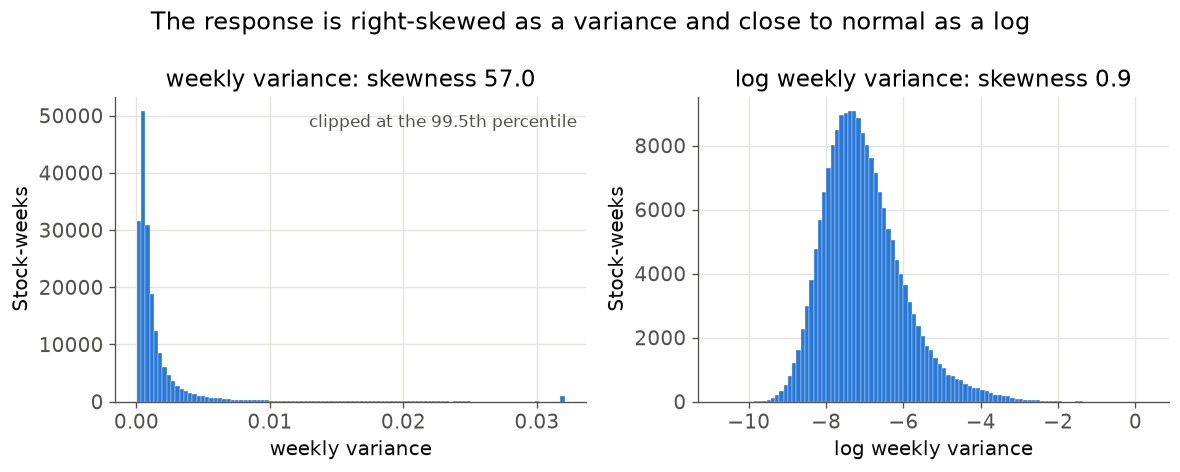

In [5]:
# EDA 2b: the response on the variance scale and on the log scale (training years)
from volforecast import plots

plots.target_scales(train["target"], IMAGES_PATH / "ms3_target_scales.png")
print(f"excess kurtosis: variance {np.exp(train['target']).kurt():.0f}, log variance {train['target'].kurt():.2f}")

**Takeaway.** Weekly variance has skewness 57 and excess kurtosis 6,847: a few crisis weeks would
dominate any squared loss on that scale. Its log has skewness 0.9 and excess kurtosis 1.3, close to
normal. **Plan:** models fit the log, as planned, with squared error; QLIKE then needs the variance,
$\exp(\hat y)$ times Duan's smearing factor, since $\exp$ of a mean log is a median, not a mean.

### 2c. Where the response varies: across companies or across weeks?

,share of variance
stock,0.223
week,0.517
stock + week,0.737


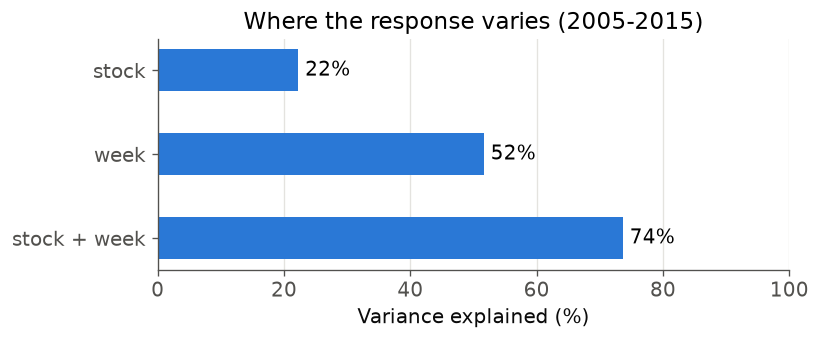

In [6]:
# EDA 2c: share of the response's variance explained by company means, week means, and both
shares = eda.variance_decomposition(train["target"], train["ticker"], train["week"])
plots.variance_decomposition(shares, IMAGES_PATH / "ms3_variance_decomposition.png")
shares.rename("share of variance").to_frame()

**Takeaway.** Week effects alone explain 52% of the variance of next week's log variance, company
effects 22%, and both together 74%: most of what moves a stock's volatility moves every stock in
that week. **Plan:** market-wide features (S&P 500 variance, VIX and its term structure) belong in
every pooled model, including a HAR baseline with them; a company's level (22%) is a second
baseline, pooled HAR with a constant per company, and the long lags `har_q`, `har_y` carry it in the
pooled models without one.

### 2d. Is next week's log variance linear in the HAR lags?

,har_d,har_w,har_m,har_q,har_y
correlation with the target,0.727,0.793,0.807,0.798,0.708


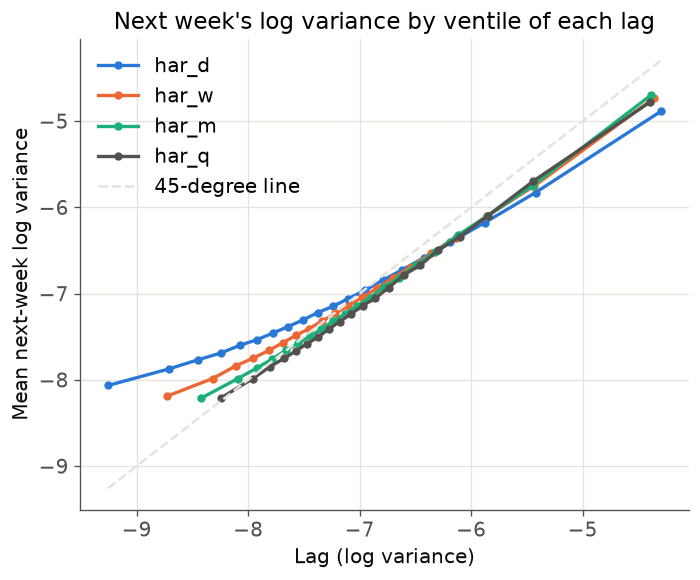

In [7]:
# EDA 2d: mean next-week log variance by ventile of each lag; a straight line means a linear fit
means = eda.binned_means(train, ["har_d", "har_w", "har_m", "har_q"], "target")
plots.binned(means, IMAGES_PATH / "ms3_har_linearity.png")
train[["har_d", "har_w", "har_m", "har_q", "har_y", "target"]].corr()["target"].drop("target").rename("correlation with the target").to_frame().T

**Takeaway.** The mean of next week's log variance rises almost linearly in each lag, with slope
below one (high volatility comes back toward the mean), so a linear model in logs is a fair
baseline. The monthly and quarterly lags track the target closest (correlations 0.81 and 0.80
against 0.73 for the last day). The last day's line flattens at the low end, where zero-range days
pull `har_d` down without moving next week. **Plan:** keep HAR linear in logs; add `har_q` and
`har_y`; a tree model can use the bend at the low end.

### 2e. Skewed and heavy-tailed features

In [8]:
# EDA 2e: skewness, excess kurtosis and missing share of every numeric feature, and its transform
from volforecast.models import BLOCKS

FEATURES = [c for block in BLOCKS.values() for c in block if c != "sic2"]  # 181 numeric features
shape = eda.tails(train, FEATURES)
HEAVY = list(shape.index[shape["transform"] == "normal scores"])
STEADY = [c for c in FEATURES if c not in HEAVY]
print(f"{len(FEATURES)} numeric features: {len(HEAVY)} heavy-tailed (excess kurtosis above "
      f"{eda.HEAVY_KURTOSIS}), {len(STEADY)} close to normal")
pd.concat([shape.head(6), shape.loc[["ret", "VIXCLS", "har_w", "VXVCLS"]]])

181 numeric features: 72 heavy-tailed (excess kurtosis above 10), 109 close to normal


,skew,kurtosis,missing,transform
VSTD5,73.799,7946.653,1.050e-05,normal scores
VMA5,73.872,6950.245,1.050e-05,normal scores
VSTD10,55.918,5789.459,2.099e-05,normal scores
VMA10,61.691,5384.200,2.099e-05,normal scores
VMA20,49.899,4422.466,3.002e-03,normal scores
VMA60,45.373,3843.911,1.514e-02,normal scores
ret,-0.629,24.677,0.000e+00,normal scores
VIXCLS,2.483,8.324,0.000e+00,standardize
har_w,0.860,1.305,0.000e+00,standardize
VXVCLS,1.833,3.872,2.254e-01,standardize


**Takeaway.** 72 of 181 numeric features have excess kurtosis above 10, mostly the Alpha158 volume
ratios (VSTD5 reaches 7,947) and weekly returns (25); the HAR lags (1.3) and VIX (8.3) are close to
normal. The 3-month VIX is missing for 22.5% of training rows (it starts in December 2007).
**Plan:** for ridge and lasso, heavy-tailed features are mapped to normal scores by rank
(`QuantileTransformer`, fit on each training window), so one extreme week cannot dominate a
coefficient; the rest are standardized; both impute 0 (the training center) and add a missing-value
flag; industry is one-hot. Trees get the raw features.

### 2f. Features that measure the same thing

rank correlation
har_w            log_rv_rs                    0.991
                 log_rv_parkinson             0.984
VIXCLS           VXVCLS                       0.976
log_rv_parkinson log_rv_rs                    0.956
har_m            har_q                        0.915

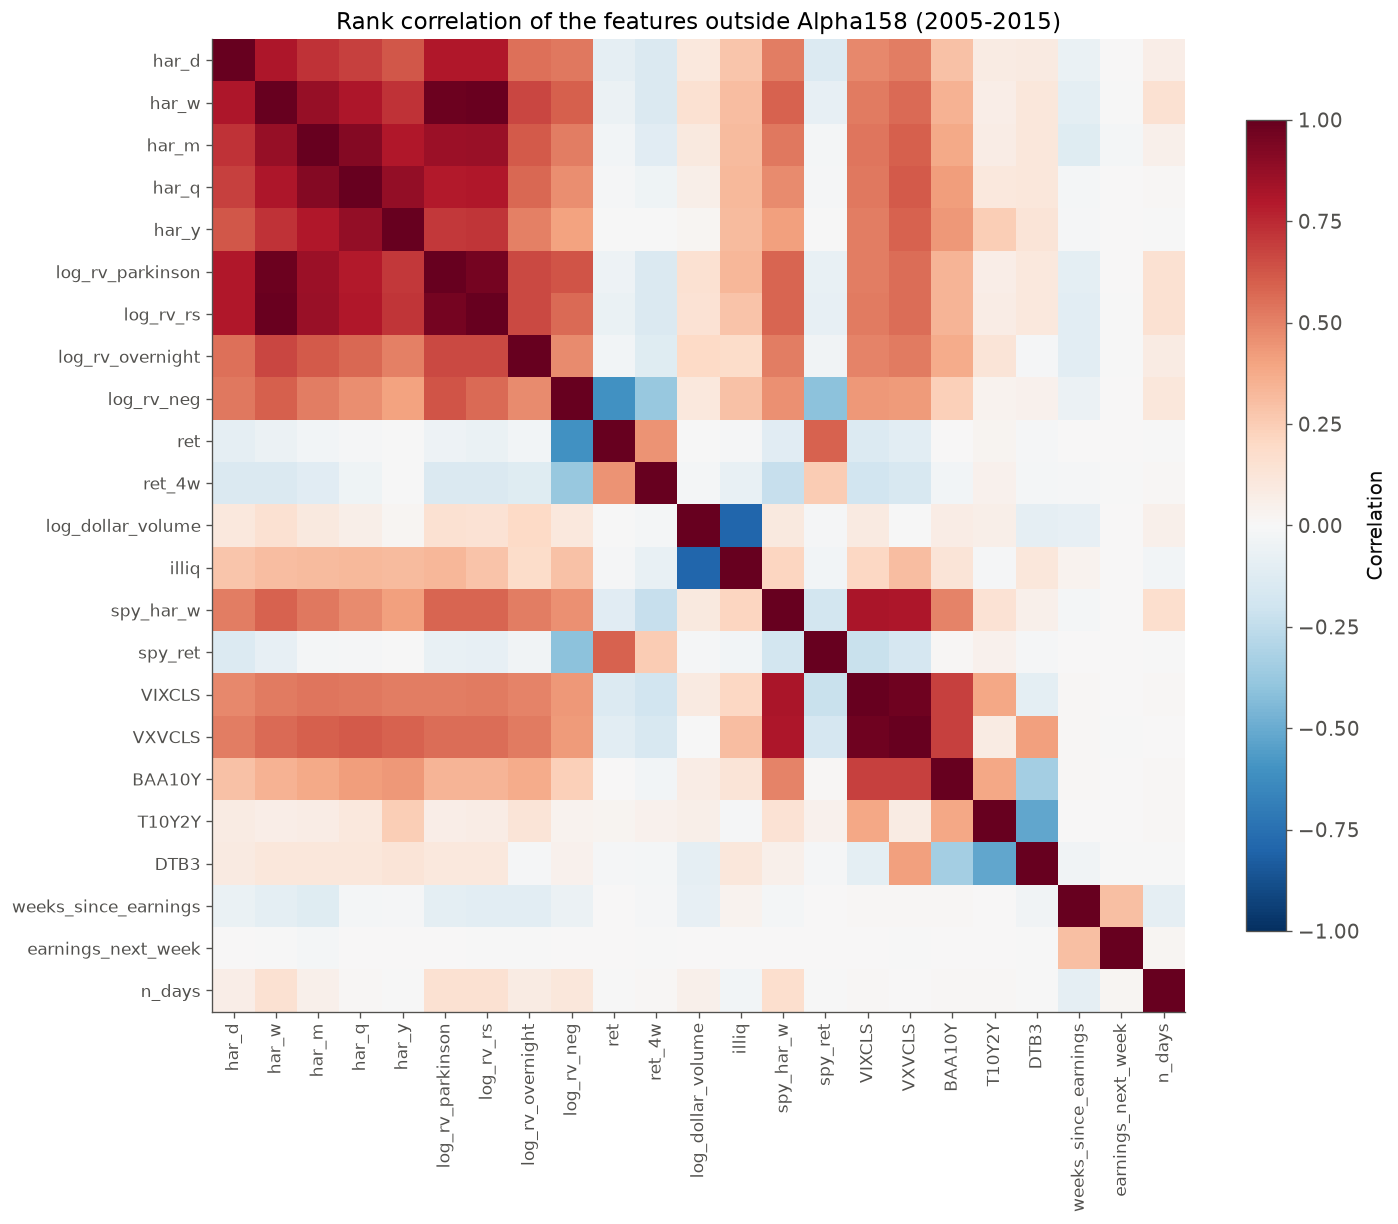

In [9]:
# EDA 2f: rank correlations among the 23 features outside Alpha158, and the pairs above 0.9
CORE = [c for name, block in BLOCKS.items() if name not in ("Alpha158", "industry") for c in block]
corr = train[CORE].rank().corr()  # Spearman: Pearson correlation of the ranks
plots.corr_heatmap(corr, "Rank correlation of the features outside Alpha158 (2005-2015)",
                   IMAGES_PATH / "ms3_core_correlation.png")
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.9].sort_values(ascending=False).rename("rank correlation").to_frame()

**Takeaway.** Several features measure nearly the same thing: the weekly Garman-Klass,
Rogers-Satchell and Parkinson variances (rank correlation 0.96 to 0.99), VIX and the 3-month VIX
(0.98), and the monthly and quarterly lags (0.92); Alpha158 adds exact duplicates (its SUMP, SUMN
and SUMD sum to constants). **Plan:** least squares on every feature would have unstable
coefficients, so the pooled linear models are ridge and lasso; Q2 drops whole blocks rather than
single features, because dropping one of a near-duplicate pair changes nothing.

### 2g. Single-factor research: which features rank stocks, and which add to HAR

Each stock-level feature is scored like a return factor on a quant desk: its **rank IC** is the
Spearman correlation, across the stocks of one week, between the feature and what it should
predict; its **ICIR** is the mean weekly IC over its standard deviation, and its hit rate the share
of weeks with the sign of the mean (Grinold and Kahn, 2000; the measures qlib and alphalens
report). Scoring against **per-stock HAR's miss** (target minus HAR's in-sample fit) measures what a
feature adds beyond the benchmark, the way a desk neutralizes a factor against its risk model.
Market-wide features take one value per week, so they have no IC; 2j covers them.

,ic,ic_std,icir,t,hit
har_d,-0.177,0.117,-1.512,-36.133,0.946
weeks_since_earnings,0.174,0.149,1.171,27.985,0.902
log_rv_rs,-0.152,0.132,-1.152,-27.530,0.884
KLEN,-0.151,0.121,-1.247,-29.807,0.923
har_w,-0.145,0.135,-1.076,-25.720,0.862
log_rv_parkinson,-0.129,0.135,-0.952,-22.741,0.830
KLOW,-0.115,0.089,-1.295,-30.950,0.912
LOW0,0.108,0.104,1.045,24.981,0.883
har_m,-0.103,0.142,-0.722,-17.259,0.769
KUP,-0.102,0.092,-1.116,-26.671,0.879


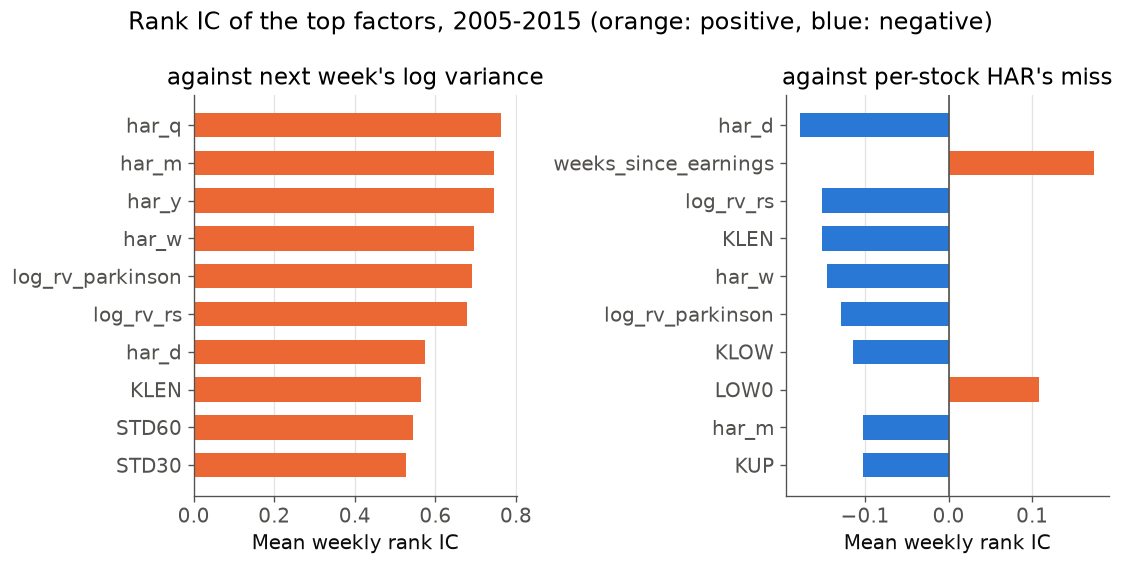

In [10]:
# EDA 2g: rank IC of every stock-level factor against the target and against HAR's miss
from volforecast import factors
from volforecast.models import PerStock

har_fit = PerStock().fit(train, train["target"])  # per-stock HAR on the training years
train = train.assign(miss=train["target"] - har_fit.predict(train))
COMMON = [*BLOCKS["market"], "n_days"]  # one value per week for every stock: no rank IC
FACTORS = [c for c in FEATURES if c not in COMMON]
ic_target, ic_miss = (factors.rank_ic(train, FACTORS, y) for y in ["target", "miss"])
s_target, s_miss = factors.ic_summary(ic_target), factors.ic_summary(ic_miss)
plots.ic_bars(s_target["ic"].head(10), s_miss["ic"].head(10), IMAGES_PATH / "ms3_factor_ic.png")
s_miss.head(10)

**Takeaway.** Against the target, every top factor is a volatility level, and the quarterly lag
ranks stocks best (mean IC 0.76, against 0.70 for last week's variance). Against HAR's miss, the
strongest factor is the last day's variance, with IC -0.18, negative in 95% of weeks: stocks with
a high last day tend to land below HAR's forecast, a hint that spikes fade faster than HAR's daily
slope assumes. A rank correlation with the miss does not prove a bias in its mean; the models of
section 4 test whether the hint pays. Next comes weeks since the last earnings release (+0.17, positive in 90% of
weeks): the longer since the last report, the nearer the next, and HAR cannot see the earnings
bump. Candle shapes (KLEN, KLOW, KUP: the day's range and shadows relative to the price) follow at
-0.10 to -0.15. These ICs are large by return-factor standards, where 0.05 is good. **Plan:** the
long-memory, earnings and Alpha158 candle blocks are the ones expected to add to HAR; Q2 tests
that.

### 2h. Factor evolution: does each factor keep its IC across years and regimes?

,har_d,weeks_since_earnings,log_rv_rs,KLEN,har_w,log_rv_parkinson,KLOW,LOW0,har_m,KUP,VSUMP60,VSUMD60
calm,-0.174,0.179,-0.147,-0.148,-0.141,-0.125,-0.113,0.106,-0.097,-0.096,-0.106,-0.106
stress,-0.208,0.131,-0.189,-0.181,-0.180,-0.163,-0.131,0.134,-0.151,-0.159,-0.067,-0.067
years with the opposite sign,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


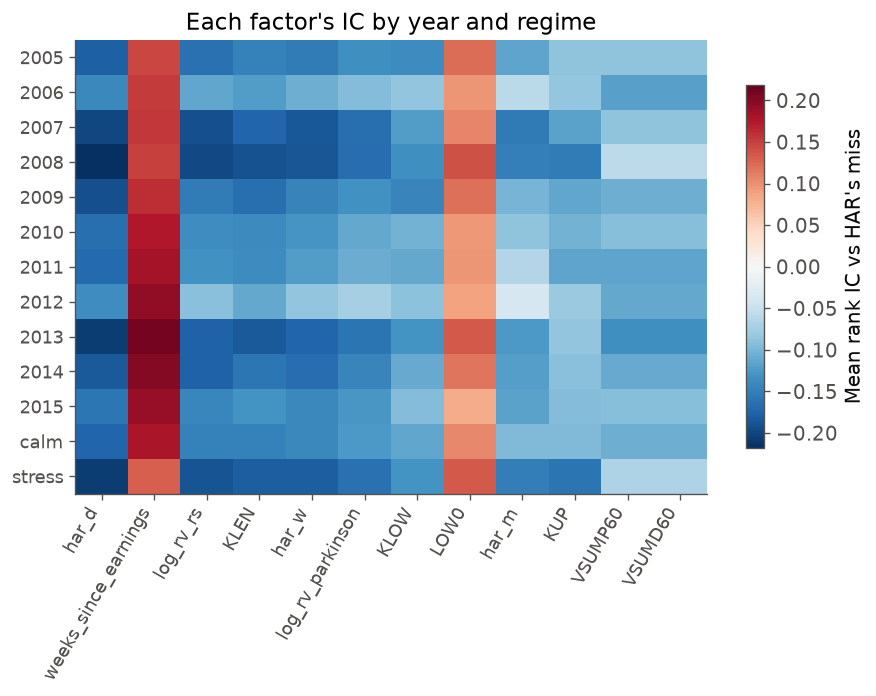

In [11]:
# EDA 2h: the top 12 factors' mean IC against HAR's miss, by year and in calm and stress weeks
TOP = list(s_miss.index[:12])
regime = train.groupby("week")["stress"].first().map({False: "calm", True: "stress"})
by_year = ic_miss[TOP].groupby(ic_miss.index.year).mean()
evolution = pd.concat([by_year.rename(index=str), ic_miss[TOP].groupby(regime).mean()])
plots.ic_heatmap(evolution, IMAGES_PATH / "ms3_factor_evolution.png")
flips = (np.sign(by_year) != np.sign(s_miss.loc[TOP, "ic"])).sum().rename("years with the opposite sign")
pd.concat([evolution.loc[["calm", "stress"]], flips.to_frame().T])

**Takeaway.** None of the twelve strongest factors changes sign in any training year, from the
2008 crisis to the calm of 2013: the information is stable, so a model fit on 2005-2015 can be
trusted on later years. The regime changes their strength: in stress weeks most factors are
stronger (the last day's -0.21 against -0.17 in calm weeks), while the earnings factor is weaker
(0.13 against 0.18), because a market-wide shock swamps a company's own calendar. **Plan:** keep the factors; report Q2's block results separately for calm and
stress weeks, as the regime may change which block matters.

### 2i. Multi-factor: how many distinct signals, and do they add up?

In [12]:
# EDA 2i: cluster the factors by rank correlation, then combine the strongest factor of each
# cluster into an ICIR-weighted composite and score it on training and validation years
labels = factors.clusters(train, FACTORS)
leaders = s_miss.groupby(labels.reindex(s_miss.index)).head(1)  # strongest factor per cluster
valid = valid.assign(miss=valid["target"] - har_fit.predict(valid))
composite = {name: rows.assign(composite=factors.composite(rows, leaders["icir"]))
             for name, rows in [("train", train), ("validation", valid)]}
print(f"{len(FACTORS)} factors form {labels.nunique()} clusters; Alpha158's 158 form "
      f"{labels[BLOCKS['Alpha158']].nunique()}")
comp_ic = pd.DataFrame({name: factors.ic_summary(factors.rank_ic(rows, ["composite", s_miss.index[0]], "miss"))[["ic", "icir"]].stack()
                        for name, rows in composite.items()}).unstack()
comp_ic

173 factors form 55 clusters; Alpha158's 158 form 50


train        validation       
              ic   icir         ic   icir
composite  0.218  2.001      0.211  1.909
har_d     -0.177 -1.512     -0.133 -1.202

**Takeaway.** The 173 stock-level factors form 55 clusters of factors that move together (average
absolute rank correlation above 0.7); Alpha158's 158 columns carry about 50 distinct signals. An
ICIR-weighted composite of the strongest factor in each cluster has IC 0.22 against HAR's miss in
training and 0.21 on the validation years it never saw, against 0.18 and 0.13 for the best single
factor. **Plan:** the information beyond HAR is spread over many weak, partly independent
signals, and combining them holds out of sample: that is the case for a pooled model on all
blocks, ridge and lasso now and gradient-boosted trees next, over a hand-picked short list.

### 2j. What the stock-level factors cannot see: the common miss, and earnings

share of HAR's miss that is common to all stocks in a week: 37%


,d_log_vix,spy_ret,log_vix,VIXCLS,VXVCLS,spy_har_w,BAA10Y,T10Y2Y,DTB3
correlation with the weekly mean miss,0.348,-0.286,0.242,0.236,0.224,0.163,0.146,0.02,0.015


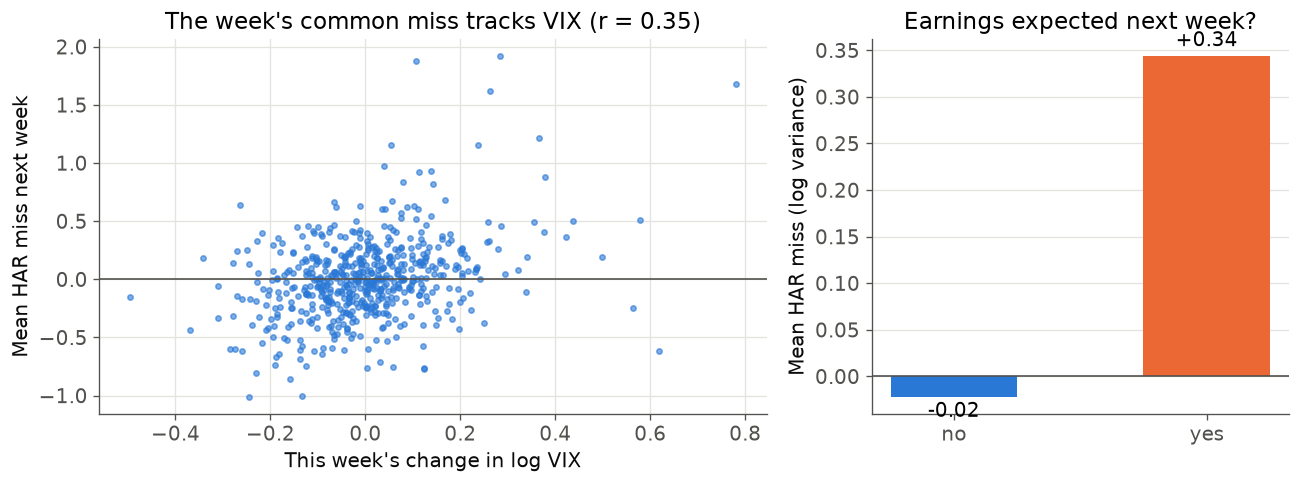

In [13]:
# EDA 2j: HAR's miss averaged over stocks each week, against market variables; and by earnings
miss_week = eda.variance_decomposition(train["miss"], train["ticker"], train["week"])["week"]
print(f"share of HAR's miss that is common to all stocks in a week: {miss_week:.0%}")
weekly = eda.common_miss(train["miss"], train["week"], train[BLOCKS["market"]])
by_flag = train.groupby(train["earnings_next_week"].map({0.0: "no", 1.0: "yes"}))["miss"].mean()
plots.common_miss(weekly, by_flag, IMAGES_PATH / "ms3_common_miss.png")
weekly.corr()["mean miss"].drop("mean miss").sort_values(key=abs, ascending=False).rename("correlation with the weekly mean miss").to_frame().T

**Takeaway.** 37% of HAR's miss is common to all stocks in a week. That common miss follows the
market: it rises with this week's change in log VIX (correlation 0.35) and after down weeks of the
S&P 500 (-0.29), and less with the VIX level (0.24). Across stocks, HAR under-forecasts by 0.34
in log variance (about 19% in volatility) when earnings are expected next week, and is unbiased
otherwise. **Plan:** the market block (S&P 500 return and variance, VIX, credit spread) addresses
the common part; we will add the weekly change in log VIX and the VIX term spread, which are not
yet columns; the earnings block addresses the stock part.

### 2k. Factor evolution by genetic programming

The factors above were designed by hand. Desks also *evolve* factors: a search over formulas of
existing features, kept if they predict out of sample (Koza, 1992; since 2025 the same search is run
with language models proposing formulas, as in AlphaAgent and QuantaAlpha). Here gplearn's
`SymbolicTransformer` evolves 600 formulas over 6 generations to maximize the rank correlation with
the cross-sectional part of HAR's miss, on 30,000 training rows; three rounds each search what the
previous formulas left unexplained, so the factors are distinct. Each one is then scored on the
validation years.

In [14]:
# EDA 2k: evolve three formulas on the training years (about a minute), then score them
GP_INPUTS = [*HAR, "har_q", "har_y", "log_rv_parkinson", "log_rv_rs", "log_rv_overnight",
             "log_rv_neg", "ret", "ret_4w", "log_dollar_volume", "illiq", "weeks_since_earnings",
             "STD20", "KLEN", "RSV20", "VSTD20", "CORR20"]
xs = {name: rows.assign(xs_miss=rows["miss"] - rows.groupby("week")["miss"].transform("mean"))
      for name, rows in [("train", train), ("validation", valid)]}  # the cross-sectional part
programs = factors.evolve(xs["train"], GP_INPUTS, "xs_miss")  # missing inputs: training medians
evolved = factors.score_evolved(programs, xs, GP_INPUTS, "xs_miss", xs["train"][GP_INPUTS].median())
evolved

,formula,"IC, train","ICIR, train","IC, validation","ICIR, validation"
f1,"add(sub(har_q, har_d), sqrt(weeks_since_earnings))",0.272,2.371,0.280,2.659
f2,"div(har_w, sqrt(VSTD20))",-0.114,-1.164,-0.110,-1.133
f3,"div(abs(RSV20), illiq)",-0.027,-0.264,-0.054,-0.518


**Takeaway.** The first evolved factor combines the two strongest findings of 2g in one formula:
the quarterly lag minus the last day (long memory against a fading spike) plus the square root of
the weeks since earnings. Its IC is 0.27 in training and 0.28 on validation, so it did not fit noise
and beats every single hand-made factor (0.18). The second scales weekly variance by the
volatility of volume (IC -0.11 in both periods); the third is weak (-0.03 and -0.05). **Plan:**
the first two enter a small library of evolved factors, a candidate block for the final models,
kept only if it adds on validation to the blocks it is built from.

### 2l. What the EDA decided

| Finding | Decision |
|---|---|
| log variance is close to normal, variance is not (2b) | fit the log; back-transform with Duan smearing for QLIKE |
| 52% of variance is common to a week, 22% to a company (2c) | market block in every pooled model; HAR + market and HAR + company-constant baselines |
| the target is linear in the lags, slope below 1 (2d) | linear HAR baselines; add `har_q`, `har_y` |
| 72 features are heavy-tailed (2e) | normal scores for those in ridge and lasso, standardize the rest, flag missing values |
| near-duplicate features (2f) | ridge and lasso, not least squares; ablation by block |
| last-day spike, earnings timing and candles add to HAR (2g), stably (2h) | these blocks are Q2's main suspects |
| many weak signals that add up out of sample (2i) | a pooled model on all blocks |
| the common miss follows VIX changes (2j) | add the change in log VIX and the VIX term spread |
| an evolved factor keeps IC 0.28 on validation (2k) | a candidate block of evolved factors |
| one stress week in validation (2a) | report validation by VIX level; stress results on the test years |

## 3. Baseline models

**What the baselines predict.** Every model forecasts `target`, next week's log Garman-Klass
variance, for every stock in the index at a Friday close. A variance forecast is
$\exp(\hat y)$ times Duan's (1983) smearing factor, the mean of $\exp(\text{residual})$ over the
model's own training rows, so QLIKE sees an unbiased variance and not a median.

**Which baselines, and why.** HAR (Corsi, 2009) is a linear regression of next week's log
variance on the last day's, week's and month's: simple, interpretable (each slope says how much of
each horizon's volatility carries forward) and, in the literature, hard to beat (Audrino and
Chassot, 2024). We fit it the three ways Zhang et al. (2024) compare for a cross-section of stocks,
which isolates what pooling adds from what market information adds:

| Model | Inputs | Fit | Role |
|---|---|---|---|
| last week | `har_w` | none | the no-change forecast, for scale |
| stock mean | company | training mean per company | the mean model |
| **per-stock HAR** | `har_d`, `har_w`, `har_m` | OLS per company (52+ weeks), else pooled | **the benchmark of Q1** |
| pooled HAR | the same | one OLS on all companies | what pooling alone does |
| pooled HAR + FE | the same | pooled slopes, a constant per company | pooling with each company's level |
| pooled HAR + market | + `spy_har_w`, `VIXCLS` | one OLS | Zhang et al.'s market commonality, HAR+VIX |
| GARCH(1,1) | daily returns | MLE per company (`arch`), 5-day forecast, calibrated by a pooled line | the classic volatility model |

**Training and validation data.** Each validation year (2016, 2017, 2018) is forecast by a model
refit on all earlier rows from 2005 on (an expanding window), keeping only rows whose target week
ended before the year starts (a 7-day embargo; `pipeline.walk_forward`). So the 2016 forecasts
come from models fit on 2005-2015 only. All rows are used except 0.2% that lack a HAR lag (the
first weeks of a company's run) and the test years 2019-2026 (from the last Friday of 2018, whose
target is the first week of 2019), which no model sees in this milestone. Every model is scored on
the same rows.

**Preprocessing.** The HAR family uses its inputs as they are: they are log variances, close to
normal (2e). GARCH uses daily close-to-close returns in percent.

**Parameters.** None is tuned for the baselines: HAR and GARCH(1,1) are fit by least squares and
maximum likelihood; the only choices are fixed in advance (52 weeks before a company gets its own
HAR fit, 500 days before its own GARCH fit).

**Metrics.** QLIKE (Patton, 2011) on the variance forecast is the primary loss: it ranks
forecasts correctly even with a noisy proxy for the true variance and punishes under-prediction
more than over-prediction, which matters for risk. MSE on the log forecast is the secondary loss.
A Diebold-Mariano test (1995) compares each model with per-stock HAR on the weekly cross-sectional
mean loss difference (156 weeks), with Newey-West errors and the Harvey, Leybourne and Newbold
(1997) small-sample correction, so the dependence among stocks within a week does not overstate
significance.

In [15]:
# Baseline 3a: every baseline, refit at the start of each validation year on all earlier rows
from volforecast import models
from volforecast.pipeline import walk_forward

returns = daily.set_index(["ticker", "date"])["ret"].sort_index()  # for GARCH
BASELINES = {
    "last week": models.LastWeek(), "stock mean": models.StockMean(),
    "per-stock HAR": models.PerStock(), "pooled HAR": models.pooled_ols(HAR),
    "pooled HAR + FE": models.FixedEffects(), "pooled HAR + market": models.pooled_ols([*HAR, *models.MARKET]),
    "GARCH(1,1)": models.Garch(returns),
}
forecasts = {name: walk_forward(model, seen, *VALID) for name, model in BASELINES.items()}
print({name: f"{len(f):,} rows" for name, f in forecasts.items()})

{'last week': '76,487 rows', 'stock mean': '76,487 rows', 'per-stock HAR': '76,487 rows', 'pooled HAR': '76,487 rows', 'pooled HAR + FE': '76,487 rows', 'pooled HAR + market': '76,487 rows', 'GARCH(1,1)': '76,487 rows'}


**Takeaway.** All seven baselines forecast all 76,487 validation rows, so they are compared on
identical rows. Each was refit three times, at the start of 2016, 2017 and 2018.

In [16]:
# Baseline 3b: the fitted HAR on the training years: pooled slopes and the spread across companies
pooled_fit = models.pooled_ols(HAR).fit(train, train["target"])[-1]
coef = pd.DataFrame({"pooled HAR": [pooled_fit.intercept_, *pooled_fit.coef_]}, index=["const", *HAR])
coef.join(har_fit.coef_.quantile([0.1, 0.5, 0.9]).T.add_prefix("per stock, q"))

,pooled HAR,"per stock, q0.1","per stock, q0.5","per stock, q0.9"
const,-0.811,-2.856,-1.304,-0.638
har_d,0.161,0.091,0.155,0.218
har_w,0.216,0.106,0.201,0.300
har_m,0.511,0.264,0.447,0.564


**Takeaway.** The pooled HAR puts most weight on the month (0.51), then the week (0.22) and the
day (0.16). The slopes sum to 0.89, below one, so volatility reverts toward its mean. Across
companies the monthly slope runs from 0.26 to 0.56 (10th to 90th percentile), around the pooled
value, and the constants differ more: pooling forces one level on every company, which the
fixed-effects baseline relaxes.

## 4. Results on the validation years

All models are scored on the same 76,487 validation rows (2016-2018); per-stock HAR is the
benchmark. A negative change is a lower loss than per-stock HAR's. "DM" is the Diebold-Mariano
statistic (negative: the model has lower loss) and "p" its p-value.

76,487 validation rows in 156 weeks


,qlike,mse,qlike vs per-stock HAR,DM qlike,p qlike,mse vs per-stock HAR,DM mse,p mse
last week,0.268,0.488,0.283,7.435,6.651e-12,0.331,9.716,1.011e-17
stock mean,0.455,0.708,1.176,8.743,3.522e-15,0.931,10.617,3.945e-20
per-stock HAR,0.209,0.367,0.000,NaN,NaN,0.000,NaN,NaN
pooled HAR,0.209,0.365,0.001,0.139,8.895e-01,-0.004,-0.462,6.445e-01
pooled HAR + FE,0.208,0.361,-0.006,-0.773,4.409e-01,-0.016,-2.524,1.260e-02
pooled HAR + market,0.205,0.359,-0.020,-2.448,1.547e-02,-0.022,-2.827,5.324e-03
"GARCH(1,1)",0.261,0.497,0.249,9.103,4.111e-16,0.355,10.004,1.732e-18


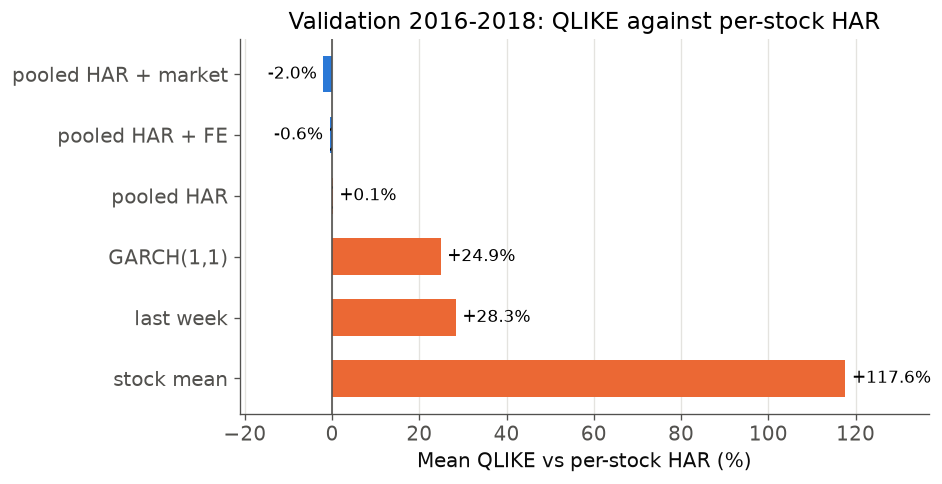

In [17]:
# Results 4a: validation QLIKE and MSE of each baseline against per-stock HAR, with DM tests
from volforecast import metrics

scores = metrics.compare(seen["target"], forecasts, BENCHMARK, seen["week"])
plots.model_scores(scores, "qlike", BENCHMARK, IMAGES_PATH / "ms3_baselines.png")
print(f"{scores.attrs['rows']:,} validation rows in {valid['week'].nunique()} weeks")
scores

**Takeaway.** Per-stock HAR has mean QLIKE 0.209 and MSE 0.367, and it is a strong benchmark:
the mean model is 118% worse, the no-change forecast 28% and GARCH(1,1) 25%. GARCH forecasts
close-to-close variance from daily returns, a noisier input than the daily range. Pooling alone
changes nothing (pooled HAR +0.1%, p = 0.89), and a constant per company helps only MSE (-1.6%,
p = 0.01). The one simple model that beats the benchmark on both losses is the pooled HAR with
market volatility: QLIKE -2.0% (p = 0.015) and MSE -2.2% (p = 0.005). This matches Zhang et al.
(2024): pooling helps through the information common to all stocks, not by itself.

### 4b. A first pooled model on every feature: ridge and lasso

In [18]:
# Results 4b: ridge and lasso on all 182 features; the penalty is chosen by validation QLIKE
from sklearn.linear_model import Lasso, Ridge

grid = {f"ridge {a:g}": Ridge(alpha=a) for a in [1e1, 1e2, 1e3, 1e4, 1e5]}
grid |= {f"lasso {a:g}": Lasso(alpha=a, precompute=True, max_iter=5000) for a in [1e-4, 3e-4, 1e-3, 3e-3]}
linear_fc = {name: walk_forward(models.linear(m, STEADY, HEAVY, ["sic2"]), seen, *VALID)
             for name, m in grid.items()}
tuning = metrics.compare(seen["target"], {BENCHMARK: forecasts[BENCHMARK], **linear_fc}, BENCHMARK, seen["week"])
CHOSEN = {kind: tuning["qlike"].filter(like=kind).idxmin() for kind in ["ridge", "lasso"]}
forecasts |= {kind: linear_fc[name] for kind, name in CHOSEN.items()}
print("chosen:", CHOSEN)
tuning[["qlike", "mse", f"qlike vs {BENCHMARK}", f"mse vs {BENCHMARK}"]]

chosen: {'ridge': 'ridge 1000', 'lasso': 'lasso 0.001'}


,qlike,mse,qlike vs per-stock HAR,mse vs per-stock HAR
per-stock HAR,0.209,0.367,0.000,0.000
ridge 10,0.177,0.310,-0.153,-0.154
ridge 100,0.177,0.310,-0.153,-0.155
ridge 1000,0.177,0.309,-0.155,-0.158
ridge 10000,0.177,0.309,-0.152,-0.157
ridge 100000,0.182,0.319,-0.129,-0.130
lasso 0.0001,0.177,0.310,-0.153,-0.156
lasso 0.0003,0.177,0.309,-0.155,-0.157
lasso 0.001,0.176,0.309,-0.156,-0.159
lasso 0.003,0.177,0.309,-0.154,-0.157


**Takeaway.** On every feature, ridge (penalty 1000) and lasso (penalty 0.001) cut QLIKE by 15.5%
and 15.6% and MSE by 15.8% and 15.9% against per-stock HAR. The score barely moves for ridge
penalties from 10 to 10,000 (15.2% to 15.5%): with 190,000 training rows the data swamp the
penalty until it gets large. This is the first answer to Q1, on validation: a pooled linear model
with cross-sectional features beats per-stock HAR by a wide margin. The penalty was chosen on these
validation years, but the curve is flat, so the choice adds little optimism; the test years will
give the unbiased size of the gain.

,qlike,qlike vs per-stock HAR,DM qlike,p qlike
per-stock HAR,0.209,0.000,NaN,NaN
+ HAR,0.209,0.001,0.102,9.188e-01
+ long memory,0.201,-0.036,-2.695,7.809e-03
+ range,0.201,-0.039,-3.437,7.558e-04
+ returns,0.199,-0.049,-4.441,1.691e-05
+ liquidity,0.198,-0.051,-4.718,5.281e-06
+ market,0.194,-0.072,-4.440,1.701e-05
+ earnings,0.182,-0.130,-7.103,4.143e-11
+ calendar,0.181,-0.132,-7.222,2.164e-11
+ Alpha158,0.177,-0.154,-7.597,2.682e-12


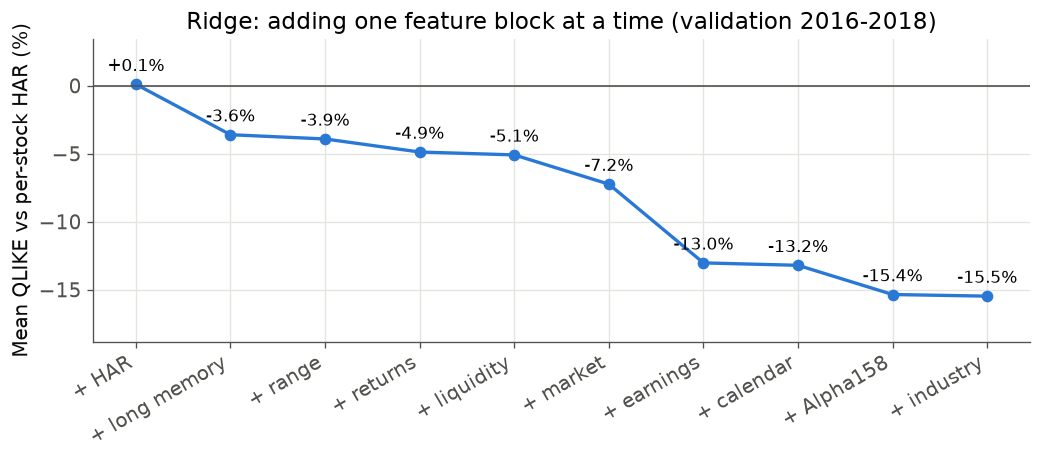

In [19]:
# Results 4c: ridge at the chosen penalty, adding one feature block at a time
ridge = grid[CHOSEN["ridge"]]
steps, columns = {}, []
for name, block in BLOCKS.items():
    columns = [*columns, *block]
    pipe = models.linear(ridge, [c for c in columns if c in STEADY], [c for c in columns if c in HEAVY],
                         [c for c in columns if c == "sic2"])
    steps[f"+ {name}"] = walk_forward(pipe, seen, *VALID)
added = metrics.compare(seen["target"], {BENCHMARK: forecasts[BENCHMARK], **steps}, BENCHMARK, seen["week"])
plots.ablation(added[f"qlike vs {BENCHMARK}"].drop(BENCHMARK), IMAGES_PATH / "ms3_blocks.png")
added[["qlike", f"qlike vs {BENCHMARK}", "DM qlike", "p qlike"]]

**Takeaway.** Adding blocks in the order of the revised question: ridge on the HAR lags alone
matches per-stock HAR (+0.1%); long memory brings -3.6%, the range, return and liquidity blocks
another 1.5 points, the market block 2.1 points (-7.2%), and the earnings block the largest single
step, 5.8 points (-13.0%); Alpha158 adds 2.2 points (-15.4%), and calendar and industry almost
nothing. The steps depend on the order, so Q2 will drop one block at a time from the full model;
this sequence already says that earnings timing, long memory, market state and Alpha158 carry the
gain.

### 4d. Where the models do well and where they do poorly

per-stock HAR  pooled HAR + market  ridge   rows
group                                  value                                                         
VIX at the Friday close                below 12              0.215                0.214  0.182  28612
                                       12-15                 0.191                0.192  0.165  24094
                                       15-20                 0.231                0.219  0.183  15141
                                       20 and above          0.201                0.182  0.181   8640
company's yearly volatility (quintile) 1                     0.240                0.243  0.209  14770
                                       2                     0.207                0.202  0.172  14770
                                       3                     0.214                0.207  0.175  14770
                                       4                     0.205                0.197  0.168  14770
                                       5                     0.182                0.178  0.153  14770
earnings expected next week            no                    0.192                0.187  0.164  60360
                                       no data               0.239                0.237  0.225  12489
                                       yes                   0.378                0.391  0.214   3638

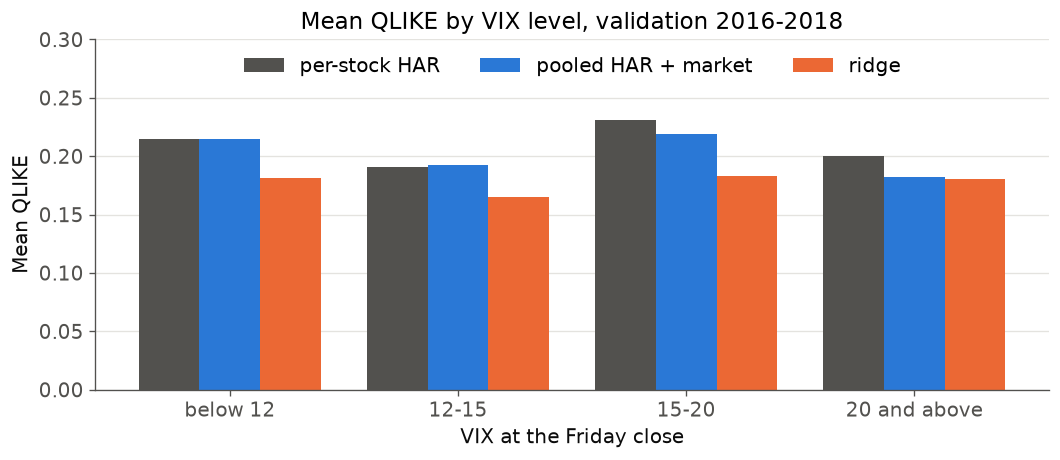

In [20]:
# Results 4d: mean QLIKE by VIX level, by the company's volatility, and around earnings
SHOW = {name: forecasts[name] for name in [BENCHMARK, "pooled HAR + market", "ridge"]}
groups = {
    "VIX at the Friday close": pd.cut(valid["VIXCLS"], [0, 12, 15, 20, 100], right=False,
                                      labels=["below 12", "12-15", "15-20", "20 and above"]),
    "company's yearly volatility (quintile)": pd.qcut(valid["har_y"], 5, labels=[1, 2, 3, 4, 5]),
    "earnings expected next week": valid["earnings_next_week"].map({0.0: "no", 1.0: "yes"}).fillna("no data"),
}
by = {name: metrics.by_group(seen["target"], SHOW, g) for name, g in groups.items()}
plots.loss_by_group(by["VIX at the Friday close"], "Mean QLIKE by VIX level, validation 2016-2018",
                    "VIX at the Friday close", IMAGES_PATH / "ms3_by_vix.png")
pd.concat(by, names=["group", "value"]).assign(**{"rows": pd.concat({n: g.value_counts() for n, g in groups.items()})})

**Takeaway.** *Where the models do well:* ridge's gain holds in every volatility quintile (13% to
18%), and it is largest in earnings weeks, where per-stock HAR's QLIKE doubles (0.378 against
0.192) and ridge cuts it to 0.214. *Where they do poorly:* when VIX is 20 or above (8,640 rows),
ridge (0.181) is level with the pooled HAR with market volatility (0.182): in turbulent weeks,
ten blocks do no better than two market inputs. Which blocks help or hurt there is a question for
Q2's drop-one-block ablation by regime. On the 12,489
rows of companies without earnings data the gain shrinks to 6%. And every model has its highest
loss on the calmest companies (quintile 1), where a rare jump costs a lot under QLIKE. **Plan:**
add the change in VIX and the VIX term spread; let a tree model learn interactions of the market
state with the stock features; fill the earnings gap.

,intercept,slope,r2
per-stock HAR,-3.256e-01,0.957,0.536
pooled HAR + market,6.580e-04,1.000,0.545
ridge,1.088e-01,1.019,0.609


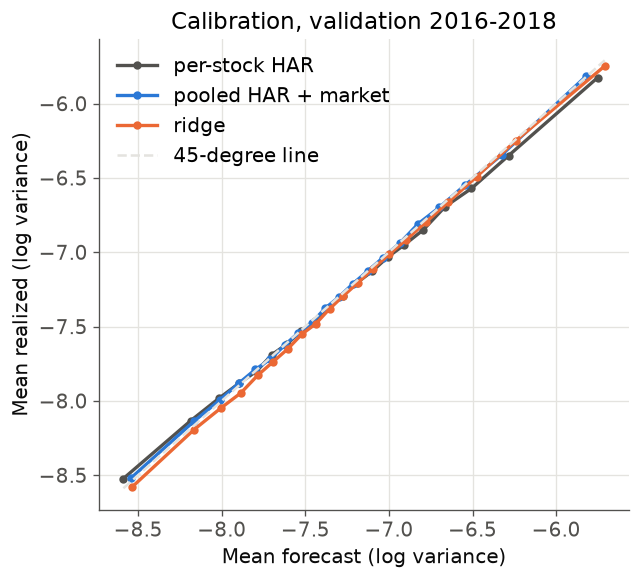

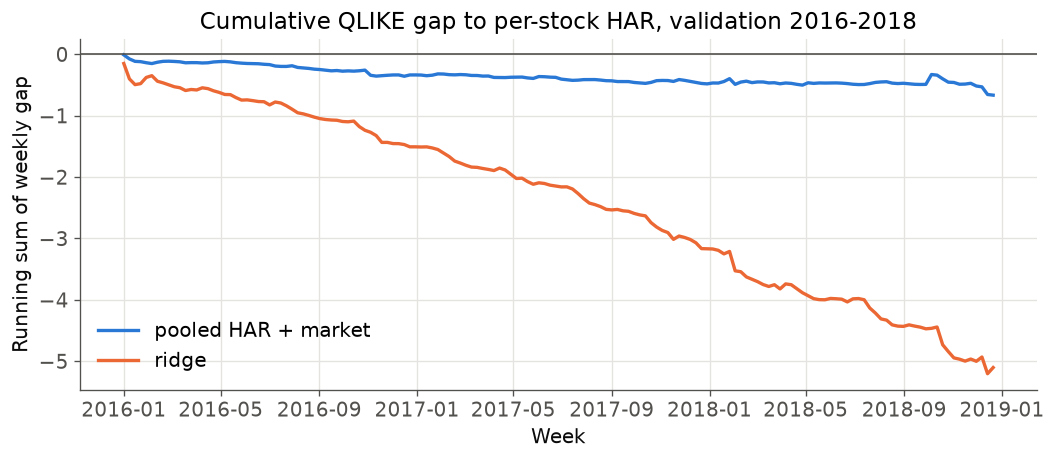

In [21]:
# Results 4e: calibration (the Mincer-Zarnowitz regression of the target on each forecast), and
# when the gains arrive (running sum of the weekly QLIKE gap to per-stock HAR)
mz = pd.DataFrame({name: metrics.mincer_zarnowitz(seen["target"], f["log_pred"]) for name, f in SHOW.items()}).T
calib = {name: eda.binned_means(seen.loc[f.index].assign(forecast=f["log_pred"]), ["forecast"], "target")
         for name, f in SHOW.items()}
plots.calibration(calib, IMAGES_PATH / "ms3_calibration.png")
weekly_qlike = pd.DataFrame({name: metrics.weekly_mean(metrics.losses(seen["target"], f), seen["week"])["qlike"]
                             for name, f in SHOW.items()})
plots.cumulative_gain(weekly_qlike, BENCHMARK, IMAGES_PATH / "ms3_cumulative_gain.png")
mz

**Takeaway.** All three forecasts are close to calibrated: regressing the target on each forecast
gives slopes of 0.96 (per-stock HAR), 1.00 and 1.02, so none needs shrinking. Ridge explains more
of the target (R² 0.61 against 0.54). The running sum of the weekly QLIKE gap to per-stock HAR
falls steadily for ridge over all three years, so its gain does not come from one lucky episode;
for the pooled HAR with market volatility it falls in 2016, then mostly flattens until a step in
late 2018.

In [22]:
# Results 4f: does the fitting scheme matter? Yearly expanding refits against a 5-year rolling
# window and against quarterly refits, for the two HAR baselines (Audrino and Chassot, 2024)
SCHEMES = {"yearly, expanding": {}, "yearly, rolling 5 years": {"window_years": 5},
           "quarterly, expanding": {"freq": "QS"}}
fits = {(model, scheme): walk_forward(BASELINES[model], seen, *VALID, **kw)
        for model in [BENCHMARK, "pooled HAR + market"] for scheme, kw in SCHEMES.items()}
pd.DataFrame({key: metrics.losses(seen["target"], f).mean() for key, f in fits.items()}).T.unstack(0)

qlike                               mse                    
                        per-stock HAR pooled HAR + market per-stock HAR pooled HAR + market
quarterly, expanding            0.209               0.205         0.364               0.358
yearly, expanding               0.209               0.205         0.367               0.359
yearly, rolling 5 years         0.212               0.206         0.372               0.360

**Takeaway.** Refitting each quarter instead of each year changes neither model's QLIKE (0.209
and 0.205), and a 5-year rolling window is slightly worse than the expanding window (0.212 and
0.206). Audrino and Chassot (2024) found that daily HAR needs frequent refits; for weekly
forecasts it does not. **Plan:** keep yearly expanding refits for every model; the refit
frequency stays a parameter in case the tree models differ.

In [23]:
# Results 4g: what ridge learned: the largest coefficients (standardized inputs) of the 2016 fit
ridge_2016 = models.linear(ridge, STEADY, HEAVY, ["sic2"]).fit(train, train["target"])
names = ridge_2016[0].get_feature_names_out()
weights = pd.Series(ridge_2016[-1].coef_, index=[n.split("__")[-1] for n in names])
lasso_2016 = models.linear(grid[CHOSEN["lasso"]], STEADY, HEAVY, ["sic2"]).fit(train, train["target"])
print(f"lasso keeps {np.sum(lasso_2016[-1].coef_ != 0)} of {len(names)} inputs")
weights.sort_values(key=abs, ascending=False).head(12).round(3).rename("ridge coefficient").to_frame().T

lasso keeps 102 of 383 inputs


,VIXCLS,VXVCLS,har_q,har_m,log_rv_parkinson,har_y,har_d,DTB3,har_w,sic2_15,missingindicator_earnings_next_week,missingindicator_VXVCLS
ridge coefficient,0.284,-0.249,0.178,0.171,0.12,0.118,0.115,0.113,0.092,0.075,-0.072,-0.072


**Takeaway.** Ridge's two largest coefficients are VIX (+0.28) and the 3-month VIX (-0.25), with
opposite signs: the model reads the VIX term structure (near-term fear above the 3-month level)
more than the VIX level. Then come the long lags (`har_q` 0.18, `har_m` 0.17, `har_y` 0.12), the
range and daily lags, and the T-bill rate. The missing-earnings flag gets -0.07: a company without
SEC data is forecast lower, a sign of the survivorship issue checked in 4h. Lasso keeps 102 of the
383 inputs (features, missing flags and industries), so most of the gain comes from a small part
of the features.

In [24]:
# Results 4h: a check for survivorship in the earnings data. Whether a row has earnings data
# depends on the company's future, and the earnings block can read that only through its
# missing-value flags, on the rows without data: the block's own gain there bounds the leak
data = valid["earnings_next_week"].notna().map({True: "earnings data", False: "no earnings data"})
row_qlike = {name: metrics.losses(seen["target"], f)["qlike"] for name, f in {**forecasts, **steps}.items()}
gain = {name: (row_qlike[name] - row_qlike[BENCHMARK]).groupby(data).mean() for name in ["pooled HAR + market", "ridge"]}
gain["earnings block"] = (row_qlike["+ earnings"] - row_qlike["+ market"]).groupby(data).mean()
leak = gain["earnings block"]["no earnings data"]
pd.DataFrame(gain).assign(rows=data.value_counts())

,pooled HAR + market,ridge,earnings block,rows
earnings_next_week,,,,
earnings data,-0.005,-0.036,-0.014,63998
no earnings data,-0.002,-0.014,-0.001,12489


**Takeaway.** The SEC's list of tickers covers only companies listed today, so whether a row has
earnings data depends on the company's future (whether it is later delisted). The earnings block
can read that only through its missing-value flags, which shift the forecasts of the rows without
data against the rest. On those rows the block gains 0.001 in QLIKE, against 0.014 on the rows with
data, where the gain comes from the earnings dates. Ridge as a whole gains 0.036 over per-stock HAR
on rows with earnings data and 0.014 on rows without. The leak adds close to nothing, but it is a
leak. **Plan:** before the final models, map past tickers to SEC CIK numbers through
EDGAR's full index so that delisted companies get their earnings dates too.

,qlike,mse,qlike vs per-stock HAR,DM qlike,p qlike,mse vs per-stock HAR,DM mse,p mse
last week,0.268,0.488,0.283,7.435,6.651e-12,0.331,9.716,1.011e-17
stock mean,0.455,0.708,1.176,8.743,3.522e-15,0.931,10.617,3.945e-20
per-stock HAR,0.209,0.367,0.000,NaN,NaN,0.000,NaN,NaN
pooled HAR,0.209,0.365,0.001,0.139,8.895e-01,-0.004,-0.462,6.445e-01
pooled HAR + FE,0.208,0.361,-0.006,-0.773,4.409e-01,-0.016,-2.524,1.260e-02
pooled HAR + market,0.205,0.359,-0.020,-2.448,1.547e-02,-0.022,-2.827,5.324e-03
"GARCH(1,1)",0.261,0.497,0.249,9.103,4.111e-16,0.355,10.004,1.732e-18
ridge,0.177,0.309,-0.155,-7.762,1.055e-12,-0.158,-7.206,2.365e-11
lasso,0.176,0.309,-0.156,-7.888,5.164e-13,-0.159,-7.469,5.485e-12


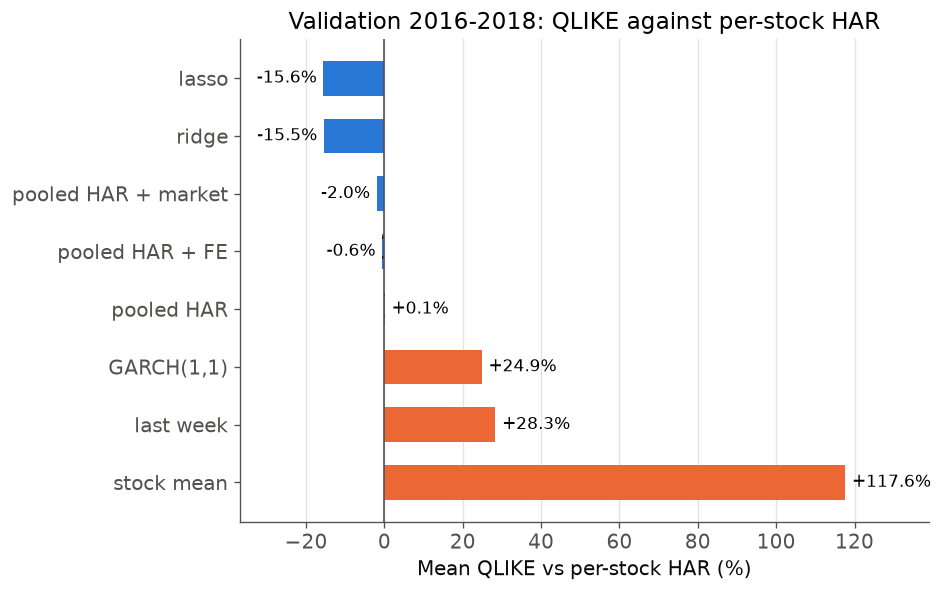

In [25]:
# Results 4i: every model of this milestone on the same validation rows
final = metrics.compare(seen["target"], forecasts, BENCHMARK, seen["week"])
plots.model_scores(final, "qlike", BENCHMARK, IMAGES_PATH / "ms3_all_models.png")
final

### 4j. Results in brief, and what changes next

- **The baseline to beat** is per-stock HAR: QLIKE 0.209 and MSE 0.367 on validation. GARCH, the
  no-change forecast and the mean model are far worse; pooling alone is a wash.
- **What works so far:** market volatility added to a pooled HAR (-2.0% QLIKE, significant), and a
  pooled ridge or lasso on every block (-15.5%, DM statistic -7.8), carried by earnings timing, long
  memory, the market block and Alpha158, steady across the three years.
- **What does not yet:** turbulent weeks (VIX 20 or above), where ridge does no better than HAR
  with two market inputs; companies without earnings data; the calmest companies.
- **Next models:** gradient-boosted trees on the same pipeline, for interactions (earnings by
  volatility level, market state by stock features) and the bend in 2d; new market features (change
  in log VIX, VIX term spread); earnings dates for delisted companies; the evolved-factor block;
  then Q2's drop-one-block ablation by regime, and a model confidence set (`arch`) next to the DM
  tests.

## 5. The modeling pipeline

```
 caches: membership, Yahoo, Alpaca, FRED, SEC          (Milestone 2; pipeline.load_tables)
    |  clean: index spells, wrong series, impossible bars, no-trade days
    v
 stock-week table: one row = (stock, Friday); target = next week's log Garman-Klass variance;
 182 features in 10 blocks, each known at that Friday's close
    |  split by target week: train 2005-2015 | validation 2016-2018 | test 2019-2026 (sealed)
    v
 walk_forward: at each refit date s (each January), fit on rows with week + 7 days < s,
 forecast the rows of [s, next s)
    |  preprocessing inside each training window (a scikit-learn Pipeline)
    v
 models: per-stock HAR | pooled HAR (+FE, +market) | GARCH | ridge, lasso | gradient-boosted trees
    |  variance forecast = exp(log forecast) x Duan smearing factor of the training window
    v
 evaluation: QLIKE, MSE | DM against per-stock HAR on weekly means (Newey-West, HLN) | VIX regimes
    |  calibration (Mincer-Zarnowitz) | Q2: drop one block, refit, score by regime
    v
 test years, once, with every choice frozen
```

1. **Data** (Milestone 2): point-in-time membership, cleaned daily prices of every past and present
   member, the stock-week table with the target and 182 features in ten blocks: HAR, long memory,
   range, returns, liquidity, market, earnings, calendar, Alpha158, industry.
2. **Sample:** drop the 0.2% of rows that lack a HAR lag; every model is scored on the same rows.
3. **Splits and refits:** train 2005-2015, validate 2016-2018, test 2019-2026. Each year is
   forecast by models refit on all earlier rows whose target week ended before it (7-day embargo).
   Validation chooses every hyperparameter; the test years are read once at the end.
4. **Preprocessing, fit on each training window:** linear models standardize the near-normal
   features, map the 72 heavy-tailed ones to normal scores, impute 0 with a missing-value flag and
   one-hot the industry; trees take raw features and missing values as they are.
5. **Models:** the baselines of section 3; ridge and lasso; gradient-boosted trees (LightGBM or
   scikit-learn's `HistGradientBoostingRegressor`) on squared error of the log; an MLP only if time
   remains.
6. **Back-transform:** variance forecast = exp(log forecast) times the smearing factor of the
   training window.
7. **Evaluation:** mean QLIKE (primary) and MSE (secondary) on identical rows; Diebold-Mariano
   tests against per-stock HAR on the weekly mean loss difference, with a Holm correction across
   models; results by regime (VIX at or above 30 on the test years) and calibration.
8. **Attribution (Q2):** refit the best model without each block in turn; report the loss change by
   regime.

**Assumptions.** The weekly Garman-Klass variance is a good proxy for the true variance (0.95
correlation with 5-minute realized variance), so QLIKE ranks models correctly (Patton, 2011). Every
feature is known at the Friday close, before the next week opens (unit tests check this by
truncation; VIX closes at 4:15 pm, and the H.15 rates are lagged a day); earnings dates are
estimated from past releases only. Relations change slowly enough that a yearly refit suffices (4f).
The weekly mean loss difference is stationary with short memory, as the DM test requires; stocks in
the same week are dependent, which the weekly mean absorbs. The validation years are calm, so they
choose penalties well but say little about stress.

**Parameters to tune on validation.**

| Model | Parameters |
|---|---|
| ridge, lasso | penalty (grid on a log scale), kurtosis threshold for normal scores (10), whether Alpha158 enters as normal scores or as ranks within each week |
| gradient-boosted trees | learning rate, number of trees (early stopping on validation), leaves per tree, minimum rows per leaf, L2 penalty, row and feature subsampling |
| every model | refit frequency (yearly or quarterly), expanding or rolling window |
| per-stock HAR, GARCH | weeks (52) or days (500) before a company gets its own fit |
| evolved factors | number kept, by validation IC |

**Who does what next** (proposed): gradient-boosted trees, Ashley; ridge and lasso with the new
market features, Shuo; HAR and GARCH on the test years and regime tables, Simon; evaluation (Holm
correction, model confidence set, regime splits), Terry; earnings dates for delisted companies,
the evolved factors and the final notebook, Juntang.

## Guard and exported numbers

The guard fails loudly if the story regresses; the export writes every number the slides quote.

In [26]:
# Guard: the claims in the takeaways above
assert not (seen["split"] == "test").any(), "a test row was read"
assert table.loc[table["split"] == "test", "target"].isna().all() and daily["date"].max() < pd.Timestamp("2019-01-01")
assert scores.loc["pooled HAR + market", "p qlike"] < 0.05 and scores.loc["pooled HAR + market", f"qlike vs {BENCHMARK}"] < 0
assert abs(scores.loc["pooled HAR", f"qlike vs {BENCHMARK}"]) < 0.01, "pooling alone should be a wash"
assert scores.loc["GARCH(1,1)", f"qlike vs {BENCHMARK}"] > 0, "GARCH should trail HAR"
assert tuning.loc[CHOSEN["ridge"], f"qlike vs {BENCHMARK}"] < -0.10, "ridge should gain over 10%"
assert evolved["IC, validation"].abs().iloc[0] > 0.2, "the first evolved factor lost its IC on validation"
assert abs(leak) < 0.005, "the earnings block now gains on rows without earnings data (survivorship, 4h)"

In [27]:
# Export the numbers the slides quote, so the two cannot drift apart
def pct(v: float) -> str:  # -0.0188 -> -1.9 percent, escaped for LaTeX
    return rf"{v * 100:+.1f}\%"


MACRO = {"last week": "LastWeek", "stock mean": "StockMean", "pooled HAR": "Pooled",
         "pooled HAR + FE": "PooledFE", "pooled HAR + market": "PooledMarket", "GARCH(1,1)": "Garch",
         "ridge": "Ridge", "lasso": "Lasso"}
numbers = {
    "nRows": f"{len(table):,}", "nTrain": f"{len(train):,}", "nValid": f"{len(valid):,}",
    "nFeatures": f"{len(FEATURES) + 1}", "nHeavy": f"{len(HEAVY)}", "nWeeks": f"{valid['week'].nunique()}",
    "leakBound": f"{leak:+.3f}",
    "shareStock": f"{shares['stock']:.0%}".replace("%", r"\%"), "shareWeek": f"{shares['week']:.0%}".replace("%", r"\%"), "shareBoth": f"{shares['stock + week']:.0%}".replace("%", r"\%"),
    "icQ": f"{s_target.loc['har_q', 'ic']:.2f}", "icW": f"{s_target.loc['har_w', 'ic']:.2f}",
    "icMissTop": s_miss.index[0].replace("_", r"\_"), "icMissTopValue": f"{s_miss['ic'].iloc[0]:+.2f}",
    "icEarn": f"{s_miss.loc['weeks_since_earnings', 'ic']:+.2f}",
    "nClusters": f"{labels.nunique()}", "nClustersAlpha": f"{labels[BLOCKS['Alpha158']].nunique()}",
    "evolvedTrain": f"{evolved['IC, train'].iloc[0]:.2f}", "evolvedValid": f"{evolved['IC, validation'].iloc[0]:.2f}",
    "ridgeAlpha": CHOSEN["ridge"].split()[1], "lassoAlpha": CHOSEN["lasso"].split()[1],
    "lassoKept": f"{np.sum(lasso_2016[-1].coef_ != 0)}", "lassoInputs": f"{len(names)}",
    "qlikeHar": f"{scores.loc[BENCHMARK, 'qlike']:.3f}", "mseHar": f"{scores.loc[BENCHMARK, 'mse']:.3f}",
}
vix, earn = by["VIX at the Friday close"], by["earnings expected next week"]
numbers |= {
    "ownFit": f"{splits.loc['tune', 'own HAR fit']:.0%}".replace("%", r"\%"),
    "stressTrain": f"{splits.loc['train', 'stress weeks']:.0f}", "stressValid": f"{splits.loc['tune', 'stress weeks']:.0f}",
    "shareMissWeek": f"{miss_week:.0%}".replace("%", r"\%"),
    "corrDVix": f"{weekly[['d_log_vix', 'mean miss']].corr().iloc[0, 1]:.2f}", "earnMiss": f"{by_flag['yes']:+.2f}",
    "compTrain": f"{comp_ic.loc['composite', ('train', 'ic')]:.2f}",
    "compValid": f"{comp_ic.loc['composite', ('validation', 'ic')]:.2f}",
    "singleTrain": f"{abs(comp_ic.loc[s_miss.index[0], ('train', 'ic')]):.2f}",
    "singleValid": f"{abs(comp_ic.loc[s_miss.index[0], ('validation', 'ic')]):.2f}",
    "earnHar": f"{earn.loc['yes', BENCHMARK]:.3f}", "earnRidge": f"{earn.loc['yes', 'ridge']:.3f}",
    "noEarnHar": f"{earn.loc['no', BENCHMARK]:.3f}",
    "highVixHar": f"{vix.loc['20 and above', BENCHMARK]:.3f}",
    "highVixMarket": f"{vix.loc['20 and above', 'pooled HAR + market']:.3f}",
    "highVixRidge": f"{vix.loc['20 and above', 'ridge']:.3f}", "nHighVix": f"{(valid['VIXCLS'] >= 20).sum():,}",
    "mzHar": f"{mz.loc[BENCHMARK, 'slope']:.2f}", "mzRidge": f"{mz.loc['ridge', 'slope']:.2f}",
    "rHar": f"{mz.loc[BENCHMARK, 'r2']:.2f}", "rRidge": f"{mz.loc['ridge', 'r2']:.2f}",
    "stepLong": pct(added.loc["+ long memory", f"qlike vs {BENCHMARK}"]),
    "stepMarket": pct(added.loc["+ market", f"qlike vs {BENCHMARK}"]),
    "stepEarnings": pct(added.loc["+ earnings", f"qlike vs {BENCHMARK}"]),
    "stepAlpha": pct(added.loc["+ Alpha158", f"qlike vs {BENCHMARK}"]),
    "skewVar": f"{np.exp(train['target']).skew():.0f}", "skewLog": f"{train['target'].skew():.1f}",
    "nFactors": f"{len(FACTORS)}", "nNumeric": f"{len(FEATURES)}",
    "evolvedTwoTrain": f"{evolved['IC, train'].iloc[1]:.2f}", "evolvedTwoValid": f"{evolved['IC, validation'].iloc[1]:.2f}",
}
for name, macro in MACRO.items():
    numbers[f"q{macro}"] = pct(final.loc[name, f"qlike vs {BENCHMARK}"])
    numbers[f"m{macro}"] = pct(final.loc[name, f"mse vs {BENCHMARK}"])
    numbers[f"p{macro}"] = f"{final.loc[name, 'p qlike']:.3f}"
tex = "\n".join(rf"\newcommand{{\{k}}}{{{v}}}" for k, v in numbers.items())
Path("deliverables/ms3").mkdir(parents=True, exist_ok=True)
Path("deliverables/ms3/numbers.tex").write_text("% Written by ms3.ipynb; do not edit.\n" + tex + "\n")
print(tex)

\newcommand{\nRows}{472,933}
\newcommand{\nTrain}{190,533}
\newcommand{\nValid}{76,487}
\newcommand{\nFeatures}{182}
\newcommand{\nHeavy}{72}
\newcommand{\nWeeks}{156}
\newcommand{\leakBound}{-0.001}
\newcommand{\shareStock}{22\%}
\newcommand{\shareWeek}{52\%}
\newcommand{\shareBoth}{74\%}
\newcommand{\icQ}{0.76}
\newcommand{\icW}{0.70}
\newcommand{\icMissTop}{har\_d}
\newcommand{\icMissTopValue}{-0.18}
\newcommand{\icEarn}{+0.17}
\newcommand{\nClusters}{55}
\newcommand{\nClustersAlpha}{50}
\newcommand{\evolvedTrain}{0.27}
\newcommand{\evolvedValid}{0.28}
\newcommand{\ridgeAlpha}{1000}
\newcommand{\lassoAlpha}{0.001}
\newcommand{\lassoKept}{102}
\newcommand{\lassoInputs}{383}
\newcommand{\qlikeHar}{0.209}
\newcommand{\mseHar}{0.367}
\newcommand{\ownFit}{83\%}
\newcommand{\stressTrain}{59}
\newcommand{\stressValid}{1}
\newcommand{\shareMissWeek}{37\%}
\newcommand{\corrDVix}{0.35}
\newcommand{\earnMiss}{+0.34}
\newcommand{\compTrain}{0.22}
\newcommand{\compValid}{0.21}
\newcommand{\singl